## **დავალებები: Machine Learning**

1. რა განსხვავებაა supervised და unsupervised Learning-ს შორის?
2. რა არის ორი ყველაზე გავრცელებული  supervised tasks?
3. ყველაზე გავრცელებული unsupervised task?
4. რა ტიპის ალგორითმს გამოიყენებთ, როცა გინდათ მომხმარებლების სხვადასხვა ჯგუფებში გადანაწილება?
5. როგორ მიიჩნევთ სპამ იმეილების აღმოჩენის პრობლემას, როგორც supervised თუ როგორც unsupervised სწავლის პრობლემად?
6. მოიყვანეთ supervised Learning-ის მაგალითი
7. როგორ ხდება მონაცემების დაყოფა და როგორ გამოიყენება შესაბამისი სიმრავლეები?
8. როგორ შეიძლება შევაფასოთ მოდელის პროგნოზი?
9. ახსენით Overfitting vs. Underfitting მანქანურ სწავლებაში
10. ახსენით Bias და Variance მანქანურ სწავლებაში

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px

### World Happiness Report

In [43]:
# World Happiness Report data
df_happiness = pd.read_csv("../../datasets/world _happiness_report/WHR.csv")
df_happiness.head()

,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,2015
4,Canada,North America and ANZ,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015


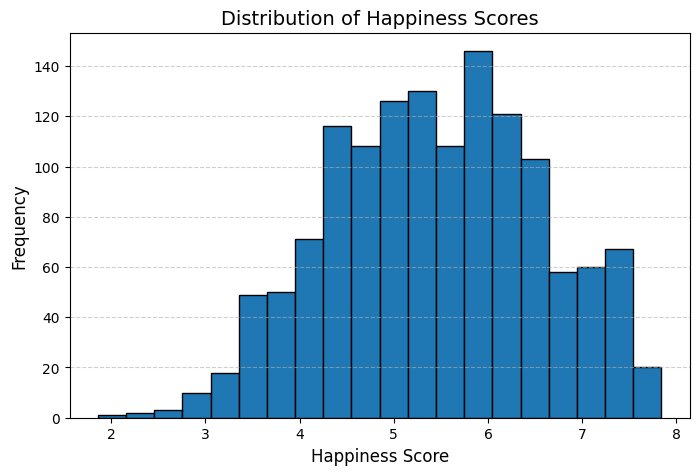

In [57]:
plt.figure(figsize=(8, 5))
plt.hist(df_happiness["happiness_score"], bins=20, edgecolor="black")

plt.title("Distribution of Happiness Scores", fontsize=14)
plt.xlabel("Happiness Score", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

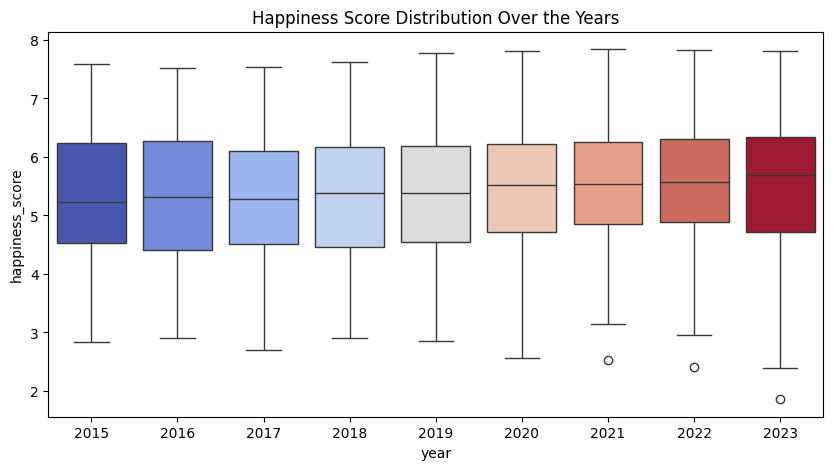

In [59]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="year", y="happiness_score", data=df_happiness, palette="coolwarm", hue="year", legend=False)
plt.title("Happiness Score Distribution Over the Years")
plt.show()

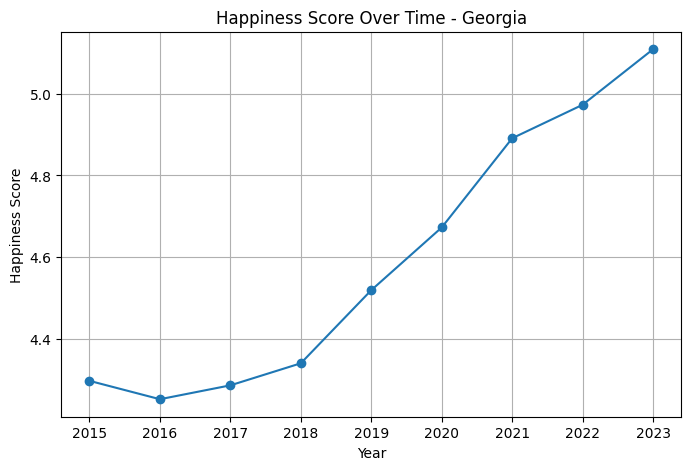

In [58]:
country = "Georgia"
country_data = df_happiness[df_happiness["country"] == country]

plt.figure(figsize=(8, 5))
plt.plot(country_data["year"], country_data["happiness_score"], marker="o")
plt.title(f"Happiness Score Over Time - {country}")
plt.xlabel("Year")
plt.ylabel("Happiness Score")
plt.grid(True)
plt.show()

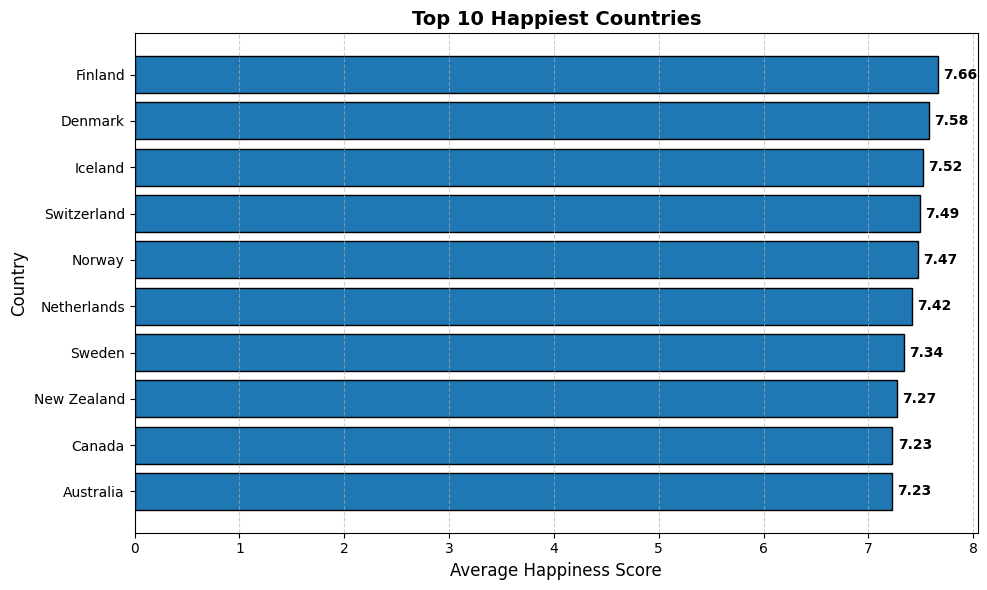

In [71]:
# Compute top 10 happiest countries
top10 = (
    df_happiness.groupby("country")["happiness_score"]
    .mean()
    .reset_index()
    .sort_values("happiness_score", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(top10["country"], top10["happiness_score"], edgecolor="black")
plt.title("Top 10 Happiest Countries", fontsize=14, fontweight="bold")
plt.xlabel("Average Happiness Score", fontsize=12)
plt.ylabel("Country", fontsize=12)
plt.gca().invert_yaxis()


for i, v in enumerate(top10["happiness_score"]):
    plt.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=10, fontweight="bold")

plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

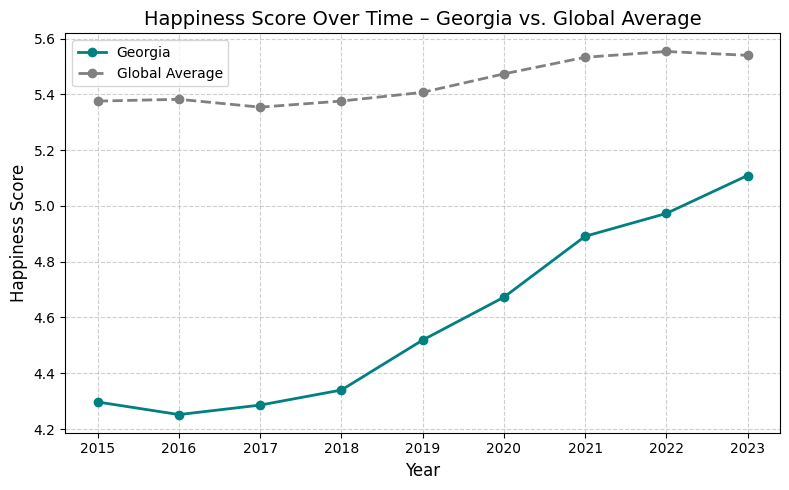

In [73]:
# Select Georgia"s data
country = "Georgia"
country_data = df_happiness[df_happiness["country"] == country]

# Compute global average per year
global_avg = (
    df_happiness.groupby("year")["happiness_score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.plot(
    country_data["year"], country_data["happiness_score"],
    marker="o", color="teal", linewidth=2, label=f"{country}"
)
plt.plot(
    global_avg["year"], global_avg["happiness_score"],
    marker="o", linestyle="--", color="gray", linewidth=2, label="Global Average"
)

plt.title(f"Happiness Score Over Time – {country} vs. Global Average", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Happiness Score", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

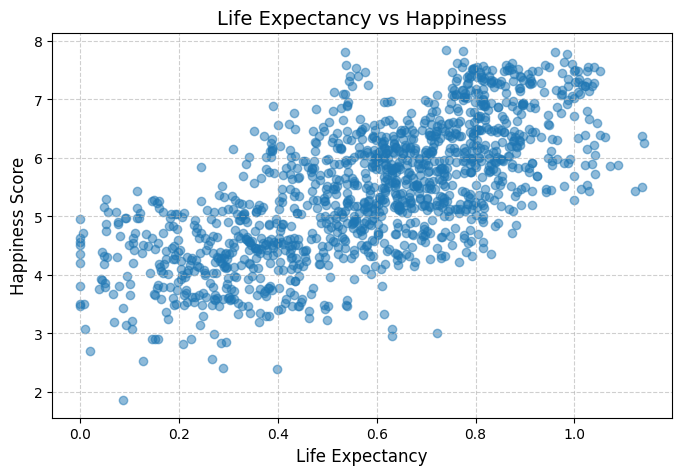

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(df_happiness["healthy_life_expectancy"], df_happiness["happiness_score"],alpha=0.5)

plt.title("Life Expectancy vs Happiness", fontsize=14)
plt.xlabel("Life Expectancy", fontsize=12)
plt.ylabel("Happiness Score", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

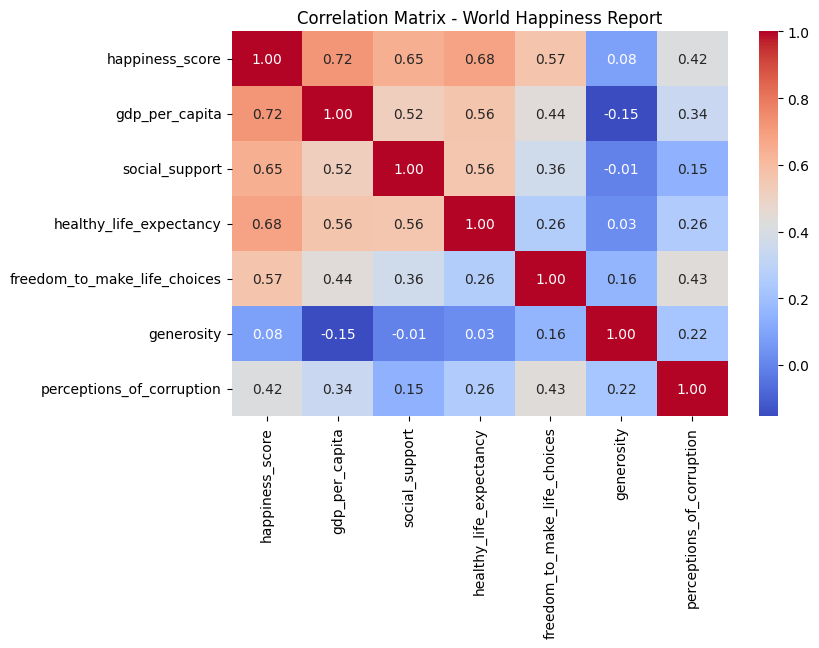

In [66]:
correlation_matrix = df_happiness[["happiness_score", "gdp_per_capita", "social_support", "healthy_life_expectancy", "freedom_to_make_life_choices", "generosity", "perceptions_of_corruption"]].corr()
plt.figure(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix - World Happiness Report")
plt.show()

### COVID-19 dataset

In [83]:
# COVID-19 dataset
url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
covid_df = pd.read_csv(url)

# დღიური ახალი შემთხვევები და სიკვდილები
worldwide_daily = covid_df.groupby("date")[["new_cases", "new_deaths"]].sum().reset_index()
worldwide_daily["total_cases"] = worldwide_daily["new_cases"].cumsum()
worldwide_daily["total_deaths"] = worldwide_daily["new_deaths"].cumsum()
worldwide_daily.head()

,date,new_cases,new_deaths,total_cases,total_deaths
0,2020-01-01,0.0,0.0,0.0,0.0
1,2020-01-02,0.0,0.0,0.0,0.0
2,2020-01-03,0.0,0.0,0.0,0.0
3,2020-01-04,0.0,0.0,0.0,0.0
4,2020-01-05,9.0,15.0,9.0,15.0


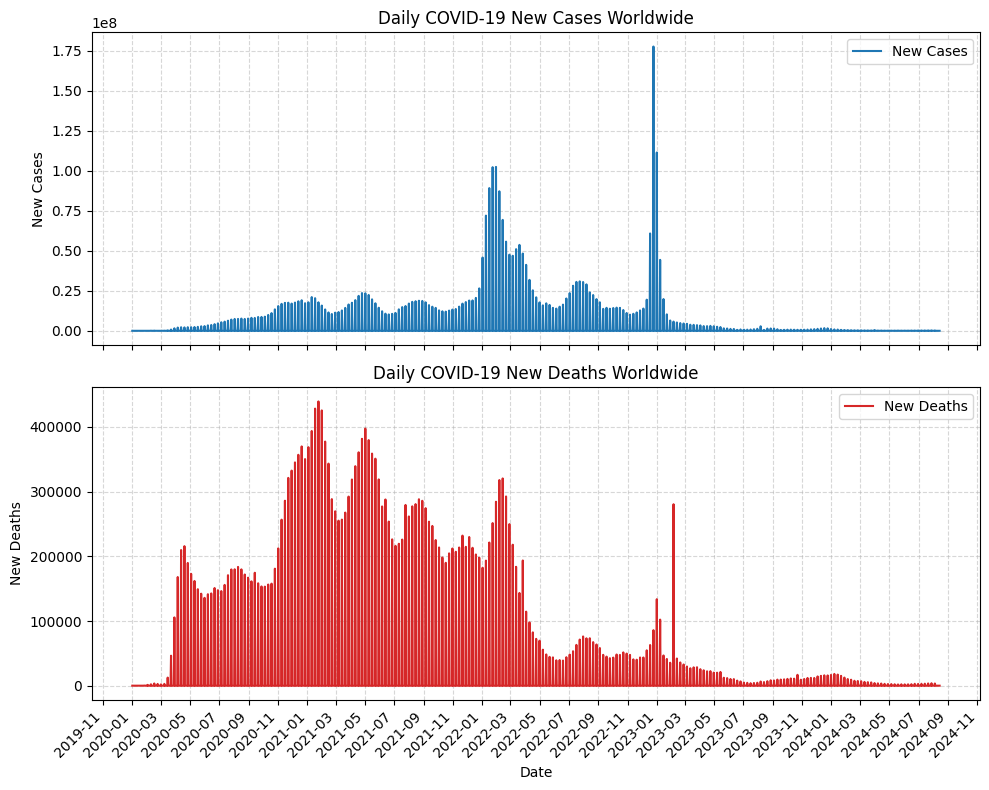

In [84]:
# Ensure datetime
worldwide_daily["date"] = pd.to_datetime(worldwide_daily["date"], errors="coerce")

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Daily new cases
ax[0].plot(worldwide_daily["date"], worldwide_daily["new_cases"], label="New Cases", color="C0")
ax[0].set_title("Daily COVID-19 New Cases Worldwide")
ax[0].set_ylabel("New Cases")
ax[0].legend()
ax[0].grid(True, linestyle="--", alpha=0.5)

# Daily new deaths
ax[1].plot(worldwide_daily["date"], worldwide_daily["new_deaths"], label="New Deaths", color="C3")
ax[1].set_title("Daily COVID-19 New Deaths Worldwide")
ax[1].set_xlabel("Date")
ax[1].set_ylabel("New Deaths")
ax[1].legend()
ax[1].grid(True, linestyle="--", alpha=0.5)

ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax[1].xaxis.get_majorticklabels(), rotation=45, ha="right")

fig.tight_layout()
plt.show()

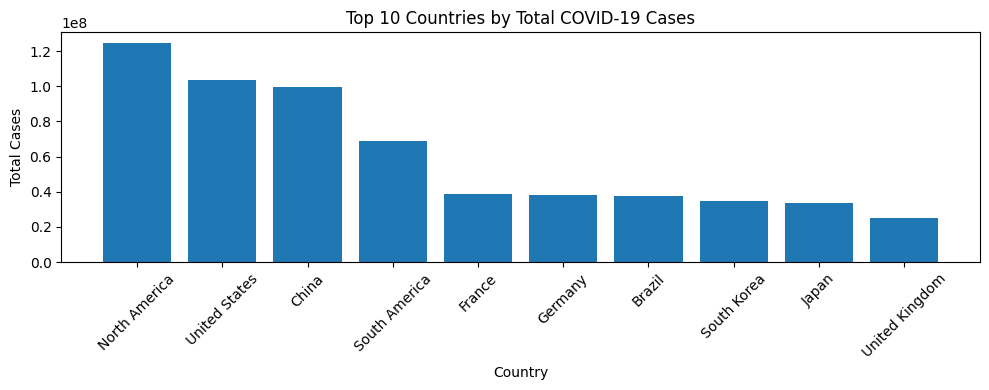

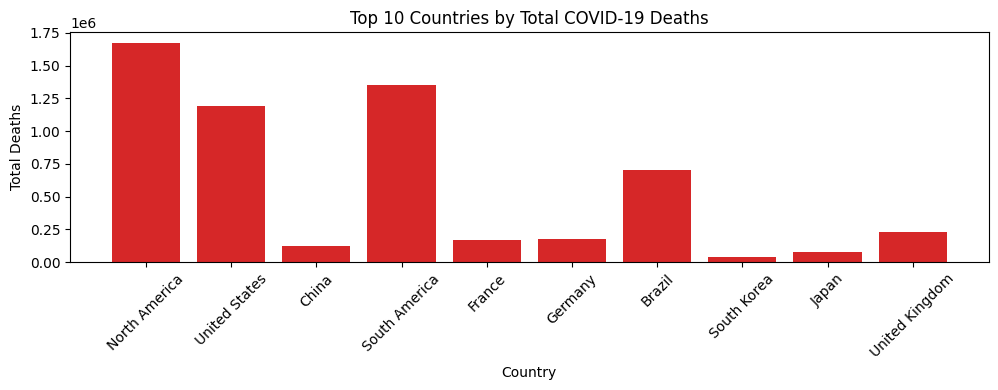

In [85]:
latest_df = covid_df.sort_values("date").groupby("location").tail(1)
top10 = latest_df.sort_values(by="total_cases", ascending=False).head(10)

countries = top10["location"]
cases = top10["total_cases"]
deaths = top10["total_deaths"]

# Top 10 ქვეყანა COVID-19-ის საერთო შემთხვევების მიხედვით
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(countries, cases, color="C0")
ax.set_title("Top 10 Countries by Total COVID-19 Cases")   
ax.set_xlabel("Country")                                  
ax.set_ylabel("Total Cases")                              
plt.xticks(rotation=45)
fig.tight_layout()

# Top 10 ქვეყანა COVID-19-ის საერთო სიკვდილების მიხედვით
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(countries, deaths, color="C3")
ax.set_title("Top 10 Countries by Total COVID-19 Deaths")
ax.set_xlabel("Country")
ax.set_ylabel("Total Deaths")
plt.xticks(rotation=45)
fig.tight_layout()

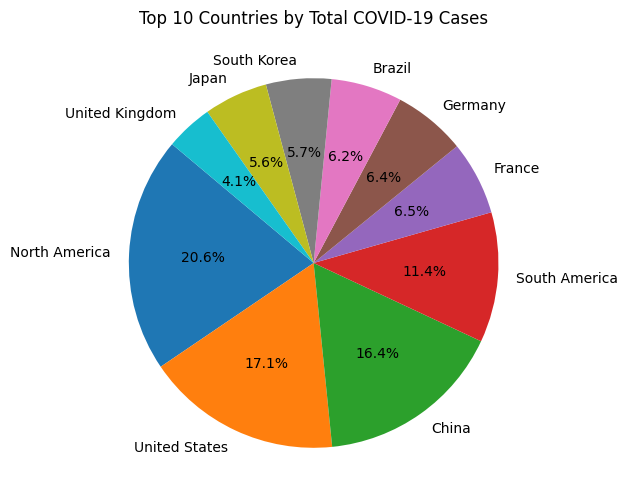

In [18]:
# Pie-Diagramm პირველი 10 ქვეყნისთვის სადაც საერთო შემთხვევების რაოდენობა ყველაზე მაღალი იყო
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(top10["total_cases"], labels=top10["location"], autopct="%1.1f%%", startangle=140)
ax.set_title("Top 10 Countries by Total COVID-19 Cases");

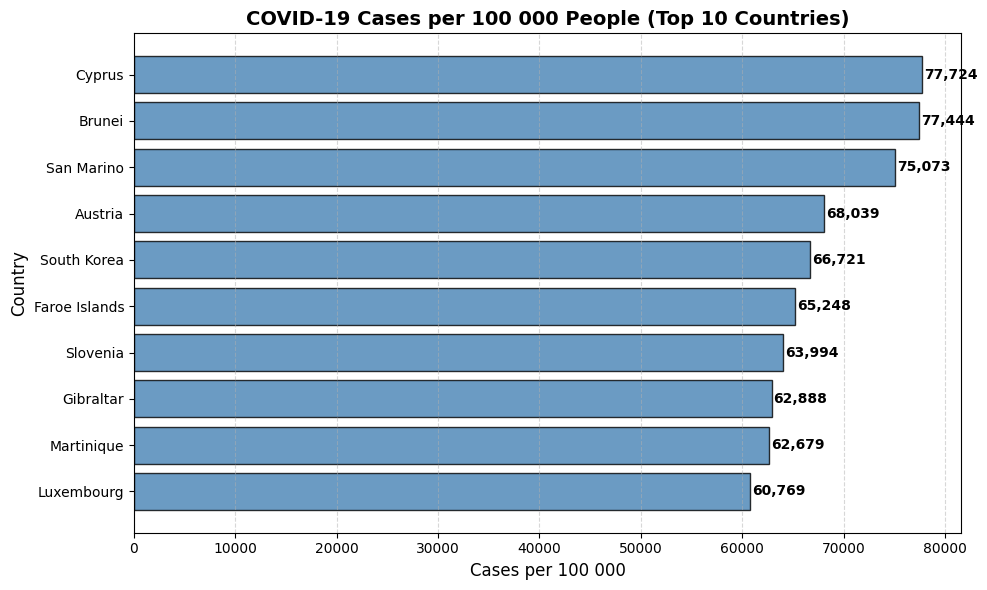

In [101]:
# რამდენი შემთხვევა გვხვდება 100 000 ადამიანზე
latest_df["cases_per_100k"] = (latest_df["total_cases"] / latest_df["population"]) * 100000
latest_df = latest_df.sort_values("cases_per_100k", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    latest_df["location"],
    latest_df["cases_per_100k"],
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

ax.invert_yaxis()

ax.set_title("COVID-19 Cases per 100 000 People (Top 10 Countries)", fontsize=14, fontweight="bold")
ax.set_xlabel("Cases per 100 000", fontsize=12)
ax.set_ylabel("Country", fontsize=12)
ax.grid(axis="x", linestyle="--", alpha=0.5)

for i, v in enumerate(latest_df["cases_per_100k"]):
    ax.text(v + 200, i, f"{v:,.0f}", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()